<a href="https://colab.research.google.com/github/AliAFar-Me/PhysioNet-Deep-Imputation-Critique/blob/main/ML_T2_017_Complete_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-T2-017: Complete Pipeline

One notebook with everything from Stage 1 through the clinical extensions. Run it top to bottom in a fresh kernel. Nothing needs to be pasted in from elsewhere.

## What it does
- Downloads PhysioNet 2012 Set-A, splits it by patient, and builds 48-hour hourly tensors.
- Trains BRITS and SAITS (seeded, gradient-clipped) and runs five classical baselines on the same masked test cells.
- Scores all 7 methods with a channel-normalized, macro-averaged MAE plus a pooled KS statistic.
- Task 1: error split by in-hospital mortality.
- Task 2: downstream mortality classifier (Random Forest) trained on each method's imputed data.
- Appendix: clipped vs. plain Adam ablation.

## Design notes
- One extraction function tracks `patient_id` and feeds both the main benchmark and Task 1.
- The classical baselines run in a single pass that keeps both the masked-point arrays and the full imputed tensors, so nothing is rebuilt later.
- Training is seeded with `set_random_seed`, which gave identical outputs across two runs at the same seed.
- The ablation sits at the end as its own section. The main benchmark doesn't depend on it.


## Part 1: Data setup


In [ ]:
# Install deps and import everything the data-prep cells need
!pip install -q pypots scikit-learn pandas numpy matplotlib seaborn

import os
import tarfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

print("Imports done.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.7/56.7 kB 3.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.9/788.9 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 64.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 51.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Libraries imported successfully!


In [ ]:
# Pull Set-A and the outcomes file; each download is skipped if the file is already on disk
DATA_DIR = './physionet_2012'
SET_A_URL = 'https://physionet.org/files/challenge-2012/1.0.0/set-a.tar.gz'
SET_A_PATH = os.path.join(DATA_DIR, 'set-a.tar.gz')
OUTCOMES_URL = 'https://physionet.org/files/challenge-2012/1.0.0/Outcomes-a.txt'
OUTCOMES_PATH = os.path.join(DATA_DIR, 'Outcomes-a.txt')

os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(SET_A_PATH):
    print("Downloading PhysioNet 2012 Set-A...")
    urllib.request.urlretrieve(SET_A_URL, SET_A_PATH)

if not os.path.exists(OUTCOMES_PATH):
    print("Downloading outcomes file (mortality labels, needed for Tasks 1 and 2)...")
    urllib.request.urlretrieve(OUTCOMES_URL, OUTCOMES_PATH)

print("Extracting files...")
with tarfile.open(SET_A_PATH, "r:gz") as tar:
    tar.extractall(path=DATA_DIR)

extract_dir = os.path.join(DATA_DIR, 'set-a')
patient_files = [f for f in os.listdir(extract_dir) if f.endswith('.txt')]

print(f"Extraction complete. Found {len(patient_files)} patient records.")


Extracting files...


/tmp/ipykernel_1929/712692444.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=DATA_DIR)


Extraction complete. Found 4000 patient records.


In [ ]:
# Split by patient, never by timestep, so no patient shows up in two folds.
# Test is 20% of all patients; val is 20% of the rest, so the real split is 64/16/20.
train_files, test_files = train_test_split(patient_files, test_size=0.2, random_state=42)
train_files, val_files = train_test_split(train_files, test_size=0.2, random_state=42)

print(f"Training Patients: {len(train_files)}")
print(f"Validation Patients: {len(val_files)}")
print(f"Testing Patients: {len(test_files)}")


Training Patients: 2560
Validation Patients: 640
Testing Patients: 800


In [ ]:
# Turn one patient's long-format file into a Time x Parameter table.
# Static fields (age, weight, ICU type, ...) are dropped; they aren't among the 36 time-series channels.
def parse_patient_file(file_path):
    df = pd.read_csv(file_path)
    static_params = ['RecordID', 'Age', 'Gender', 'Height', 'ICUType', 'Weight']
    ts_data = df[~df['Parameter'].isin(static_params)].copy()
    ts_data['Elapsed_Minutes'] = ts_data['Time'].apply(
        lambda x: int(x.split(':')[0]) * 60 + int(x.split(':')[1])
    )
    pivoted = ts_data.pivot_table(
        index='Elapsed_Minutes', columns='Parameter', values='Value', aggfunc='mean'
    )
    return pivoted

# quick check on one training file
test_file_path = os.path.join(extract_dir, train_files[0])
sample_df = parse_patient_file(test_file_path)
print(f"Parsed Patient Data Shape: {sample_df.shape}")
display(sample_df.head(10))


Parsed Patient Data Shape: (75, 23)


Parameter,BUN,Creatinine,DiasABP,FiO2,GCS,Glucose,HCO3,HCT,HR,K,...,NIMAP,NISysABP,Na,Platelets,RespRate,SysABP,Temp,TroponinT,Urine,WBC
Elapsed_Minutes,,,,,,,,,,,,,,,,,,,,,
4,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,99.0,NaN,...,75.0,127.0,NaN,NaN,26.0,NaN,36.7,NaN,NaN,NaN
19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,103.0,NaN,...,NaN,NaN,NaN,NaN,26.0,NaN,NaN,NaN,NaN,NaN
34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.0,NaN,...,66.0,124.0,NaN,NaN,22.0,NaN,NaN,NaN,NaN,NaN
64,NaN,NaN,72.0,NaN,NaN,NaN,NaN,NaN,148.0,NaN,...,89.0,114.0,NaN,NaN,22.0,137.0,NaN,NaN,1200.0,NaN
69,NaN,NaN,69.0,NaN,NaN,NaN,NaN,NaN,146.0,NaN,...,NaN,NaN,NaN,NaN,17.0,135.0,NaN,NaN,NaN,NaN
74,NaN,NaN,76.0,NaN,NaN,NaN,NaN,NaN,141.0,NaN,...,NaN,NaN,NaN,NaN,28.0,154.0,NaN,NaN,NaN,NaN
79,NaN,NaN,68.0,NaN,NaN,NaN,NaN,NaN,131.0,NaN,...,NaN,NaN,NaN,NaN,23.0,137.0,NaN,NaN,NaN,NaN
94,NaN,NaN,59.0,NaN,NaN,NaN,NaN,NaN,142.0,NaN,...,NaN,NaN,NaN,NaN,21.0,119.0,NaN,NaN,50.0,NaN
109,16.0,0.8,NaN,NaN,NaN,206.0,30.0,NaN,NaN,3.3,...,NaN,NaN,143.0,NaN,NaN,NaN,NaN,0.34,NaN,NaN


### Missingness EDA (optional, slow, safe to skip)


Processing a batch of training patients for EDA...


100%|██████████| 300/300 [00:02<00:00, 144.75it/s]
/tmp/ipykernel_1929/3766316671.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_readings.index, y=avg_readings.values, palette="mako")


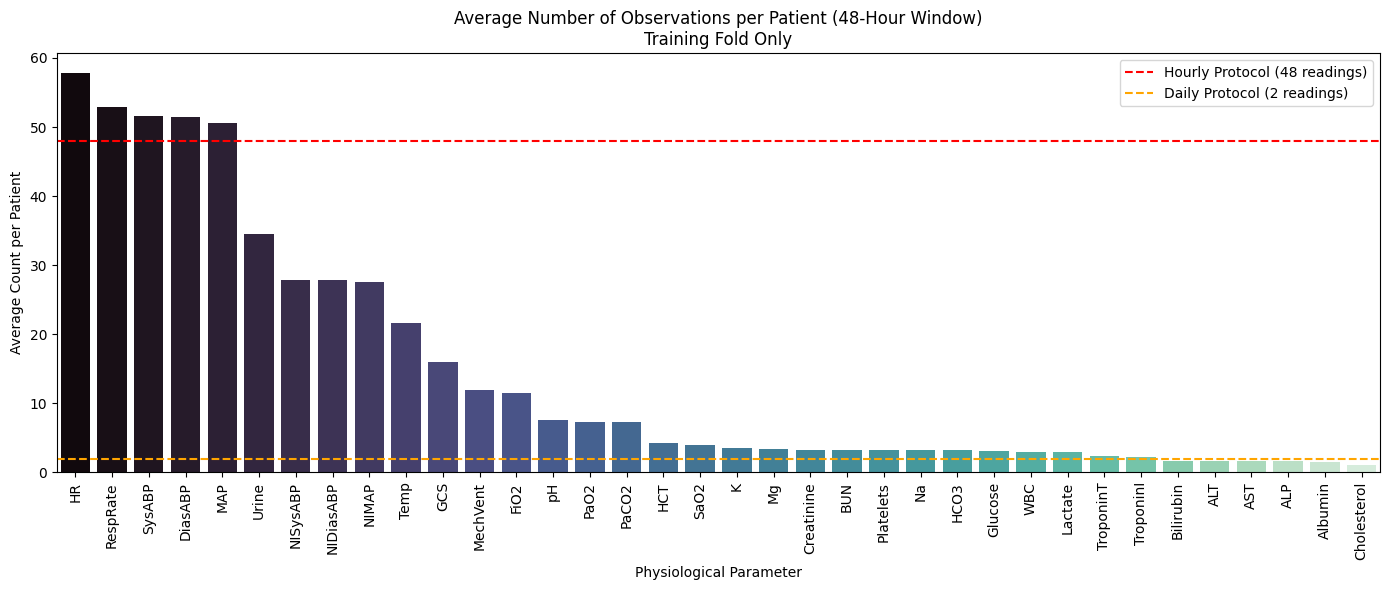

In [ ]:
# How often is each channel observed? Training patients only, so EDA never touches val/test.
from tqdm import tqdm

print("Counting observations for a sample of training patients...")
# 300 patients is enough for the picture and keeps this cell fast
sample_train_files = train_files[:300]
observation_counts = []
for file in tqdm(sample_train_files):
    file_path = os.path.join(extract_dir, file)
    df = parse_patient_file(file_path)
    observation_counts.append(df.notna().sum())

eda_df = pd.DataFrame(observation_counts)
avg_readings = eda_df.mean().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=avg_readings.index, y=avg_readings.values, palette="mako")
plt.axhline(y=48, color='red', linestyle='--', label='Hourly Protocol (48 readings)')
plt.axhline(y=2, color='orange', linestyle='--', label='Daily Protocol (2 readings)')
plt.xticks(rotation=90)
plt.title("Average Number of Observations per Patient (48-Hour Window)\nTraining Fold Only")
plt.ylabel("Average Count per Patient")
plt.xlabel("Physiological Parameter")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Average readings within each hour; reindex to 48 rows so every patient has the same shape.
def discretize_to_hourly(parsed_df):
    parsed_df['Hour'] = parsed_df.index // 60
    hourly_df = parsed_df.groupby('Hour').mean()
    hourly_df = hourly_df.reindex(range(48))
    return hourly_df

hourly_sample = discretize_to_hourly(sample_df)
print(f"Hourly Discretized Shape: {hourly_sample.shape}")
display(hourly_sample.head(5))


Hourly Discretized Shape: (48, 23)


Parameter,BUN,Creatinine,DiasABP,FiO2,GCS,Glucose,HCO3,HCT,HR,K,...,NIMAP,NISysABP,Na,Platelets,RespRate,SysABP,Temp,TroponinT,Urine,WBC
Hour,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,NaN,15.0,NaN,NaN,NaN,101.333333,NaN,...,70.5,125.5,NaN,NaN,24.666667,NaN,36.7,NaN,NaN,NaN
1,16.0,0.8,68.8,NaN,NaN,206.0,30.0,NaN,141.600000,3.3,...,89.0,114.0,143.0,NaN,22.200000,136.4,NaN,0.34,625.0,NaN
2,NaN,NaN,60.8,NaN,NaN,NaN,NaN,NaN,120.600000,NaN,...,NaN,NaN,NaN,NaN,24.000000,121.0,NaN,NaN,38.0,NaN
3,NaN,NaN,61.5,NaN,NaN,NaN,NaN,NaN,117.750000,NaN,...,NaN,NaN,NaN,NaN,25.000000,123.0,NaN,NaN,45.0,NaN
4,NaN,NaN,69.0,NaN,15.0,NaN,NaN,NaN,122.000000,NaN,...,NaN,NaN,NaN,NaN,22.500000,128.0,36.5,NaN,60.0,NaN


In [ ]:
# Hide a random 20% of the observed cells and keep their true values as ground truth.
def generate_synthetic_mask(df, mask_ratio=0.2, seed=42):
    # reseeded on every call, so a given patient gets the same mask for every method
    np.random.seed(seed)
    masked_df = df.copy()
    observed_coords = [
        (r, c) for r in df.index for c in df.columns if pd.notna(df.loc[r, c])
    ]
    n_to_mask = int(len(observed_coords) * mask_ratio)
    mask_indices = np.random.choice(len(observed_coords), size=n_to_mask, replace=False)
    masked_coords = [observed_coords[i] for i in mask_indices]
    ground_truth = []
    for r, c in masked_coords:
        ground_truth.append(df.loc[r, c])
        masked_df.loc[r, c] = np.nan
    return masked_df, np.array(ground_truth), masked_coords

print("Masking function defined.")


Synthetic masking engine ready!


## Part 2: Config, helpers, extra imports


In [ ]:
# Extra imports: models, baselines, metrics
import time
import torch
from collections import defaultdict
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import ks_2samp
import warnings
warnings.filterwarnings('ignore')  # hides sklearn/pypots warning spam; remove when debugging

from pypots.imputation import BRITS, SAITS
from pypots.optim import Adam
from pypots.utils.random import set_random_seed

# Outcomes file -> {RecordID: died in hospital (0/1)}. Defined here so both clinical tasks can use it.
def build_mortality_lookup(outcomes_path=None):
    if outcomes_path is None:
        outcomes_path = os.path.join(DATA_DIR, 'Outcomes-a.txt')
    outcomes = pd.read_csv(outcomes_path)
    return dict(zip(outcomes['RecordID'], outcomes['In-hospital_death']))

mortality_lookup = build_mortality_lookup()

Channel list, clamping bounds, and the heavy-tailed channels that get a `log1p` transform.

> **Note:** the bounds are wide sanity limits meant to catch broken model outputs. They are not clinical reference ranges and haven't been reviewed by a clinician.


In [ ]:
ALL_36_CHANNELS = [
    'ALP', 'ALT', 'AST', 'Albumin', 'BUN', 'Bilirubin', 'Cholesterol', 'Creatinine',
    'DiasABP', 'FiO2', 'GCS', 'Glucose', 'HCO3', 'HCT', 'HR', 'K', 'Lactate', 'Mg',
    'MAP', 'MechVent', 'Na', 'NIDiasABP', 'NIMAP', 'NISysABP', 'PaCO2', 'PaO2', 'pH',
    'Platelets', 'RespRate', 'SaO2', 'SysABP', 'Temp', 'TroponinI', 'TroponinT',
    'Urine', 'WBC',
]
assert len(ALL_36_CHANNELS) == 36

# Wide sanity limits for clamping model outputs, not clinical normal ranges
PHYSIOLOGICAL_BOUNDS = {
    'ALP': (0, 2000), 'ALT': (0, 5000), 'AST': (0, 5000), 'Albumin': (0.5, 6.0),
    'BUN': (0, 300), 'Bilirubin': (0, 50), 'Cholesterol': (0, 500), 'Creatinine': (0, 20),
    'DiasABP': (0, 200), 'FiO2': (0.2, 1.0), 'GCS': (3, 15), 'Glucose': (0, 1000),
    'HCO3': (0, 60), 'HCT': (0, 80), 'HR': (0, 300), 'K': (1.0, 10.0), 'Lactate': (0, 30),
    'Mg': (0.5, 10.0), 'MAP': (0, 250), 'MechVent': (0, 1), 'Na': (100, 200),
    'NIDiasABP': (0, 200), 'NIMAP': (0, 250), 'NISysABP': (0, 300), 'PaCO2': (0, 150),
    'PaO2': (0, 700), 'pH': (6.5, 8.0), 'Platelets': (0, 1000), 'RespRate': (0, 80),
    'SaO2': (0, 100), 'SysABP': (0, 300), 'Temp': (30, 45), 'TroponinI': (0, 50),
    'TroponinT': (0, 10), 'Urine': (0, 2000), 'WBC': (0, 200),
}
_missing_bounds = set(ALL_36_CHANNELS) - set(PHYSIOLOGICAL_BOUNDS)
assert not _missing_bounds, f"Missing physiological bounds for: {_missing_bounds}"

# Right-skewed channels; log1p stops a few huge values from dominating the loss
HEAVY_TAILED_CHANNELS = ['AST', 'ALT', 'Bilirubin', 'Urine']


### Helpers: clamping, `log1p`, and inverse transforms (DataFrame and tensor versions)


In [ ]:
# Clip to the bounds so extrapolated predictions can't leave the plausible range
def clamp_to_physiological_bounds(df_or_array, channel_names=None):
    if isinstance(df_or_array, pd.DataFrame):
        out = df_or_array.copy()
        for c in out.columns:
            if c in PHYSIOLOGICAL_BOUNDS:
                lo, hi = PHYSIOLOGICAL_BOUNDS[c]
                out[c] = out[c].clip(lower=lo, upper=hi)
        return out
    else:
        arr = np.asarray(df_or_array, dtype=float).copy()
        assert channel_names is not None and len(channel_names) == len(arr)
        for i, c in enumerate(channel_names):
            if c in PHYSIOLOGICAL_BOUNDS:
                lo, hi = PHYSIOLOGICAL_BOUNDS[c]
                arr[i] = np.clip(arr[i], lo, hi)
        return arr


def apply_heavy_tail_transform(df):
    out = df.copy()
    for c in HEAVY_TAILED_CHANNELS:
        if c in out.columns:
            # clip(lower=0) so a negative data-entry value can't turn log1p into NaN
            out[c] = np.log1p(out[c].clip(lower=0))
    return out


def unscale_and_untransform_frame(scaled_df, train_mean, train_std):
    """DataFrame version, used by the kNN/MICE baselines."""
    unscaled = (scaled_df * train_std) + train_mean
    for c in HEAVY_TAILED_CHANNELS:
        if c in unscaled.columns:
            unscaled[c] = np.expm1(unscaled[c])
    return unscaled


def unscale_untransform_clamp_tensor(tensor_scaled):
    """Tensor version, shape (N_patients, 48, 36). Task 2 needs full imputed
    tensors. Checked on a synthetic tensor: heavy-tailed channels stay
    non-negative after expm1 and every channel stays inside its clamp bounds."""
    mean_vec = np.array([train_mean[c] for c in column_names]).reshape(1, 1, -1)
    std_vec = np.array([train_std[c] for c in column_names]).reshape(1, 1, -1)
    t = tensor_scaled * std_vec + mean_vec
    for c in HEAVY_TAILED_CHANNELS:
        idx = col_to_idx[c]
        t[:, :, idx] = np.expm1(t[:, :, idx])
    for c, (lo, hi) in PHYSIOLOGICAL_BOUNDS.items():
        idx = col_to_idx[c]
        t[:, :, idx] = np.clip(t[:, :, idx], lo, hi)
    return t


## Part 3: Training stats and tensor construction

- `log1p` goes on the heavy-tailed channels *before* `train_mean` / `train_std` are computed, so the models train and validate entirely in the transformed space.
- `train_std` has a zero guard so constant columns don't divide by zero.
- Stats come from the training fold only.


In [ ]:
print(f"Discretizing all {len(train_files)} training patients...")
train_dfs = []
for file in tqdm(train_files):
    file_path = os.path.join(extract_dir, file)
    parsed_df = parse_patient_file(file_path)
    hourly_df = discretize_to_hourly(parsed_df)
    train_dfs.append(hourly_df)

train_dfs_transformed = [apply_heavy_tail_transform(df) for df in train_dfs]
full_train_data = pd.concat(train_dfs_transformed, ignore_index=True)

# stats from training patients only, so nothing leaks from val/test
train_mean = full_train_data.mean()
train_std = full_train_data.std().replace(0, 1.0)  # 1.0 instead of 0 so constant columns don't divide by zero
column_names = train_mean.index.tolist()
col_to_idx = {c: i for i, c in enumerate(column_names)}

print(f"Total training time-steps processed: {len(full_train_data)}")
print(f"Heavy-tailed channels transformed: {HEAVY_TAILED_CHANNELS}")


Discretizing all 2560 training patients...


100%|██████████| 2560/2560 [00:19<00:00, 129.54it/s]


Total training time-steps processed: 122880
Heavy-tailed channels transformed: ['AST', 'ALT', 'Bilirubin', 'Urine']


One tensor builder for all three folds, so they can't get mixed up:

- **Train:** `apply_synthetic_mask=False`. Natural missingness only.
- **Validation:** `apply_synthetic_mask=True, need_ori=True`. Adds the 20% mask and returns `X_ori`, which PyPOTS needs to compute a real validation loss. Used for early stopping only.
- **Test:** `apply_synthetic_mask=True, need_ori=False`. The only fold used for reported numbers.

Patients with nothing to mask are skipped, so a tensor can have fewer patients than its file list. `files_processed` records who is left.


In [ ]:
def build_tensor_set(file_list, apply_synthetic_mask, mask_ratio=0.2, need_ori=False):
    X_list, X_ori_list = [], []
    ground_truth_list, coords_list = [], []
    files_processed = []

    for file in file_list:
        file_path = os.path.join(extract_dir, file)
        parsed = parse_patient_file(file_path)
        hourly = discretize_to_hourly(parsed)

        if apply_synthetic_mask:
            masked_data, ground_truth, coords = generate_synthetic_mask(hourly, mask_ratio=mask_ratio)
            # nothing maskable -> patient is dropped, so the tensor can be shorter than file_list;
            # files_processed records who is left
            if len(ground_truth) == 0:
                continue
            ground_truth_list.append(ground_truth)
            coords_list.append(coords)
        else:
            masked_data = hourly

        masked_scaled = (apply_heavy_tail_transform(masked_data) - train_mean) / train_std
        X_list.append(masked_scaled.values)
        files_processed.append(file)

        if need_ori:
            ori_scaled = (apply_heavy_tail_transform(hourly) - train_mean) / train_std
            X_ori_list.append(ori_scaled.values)

    result = {"X": np.array(X_list)}
    if need_ori:
        result["X_ori"] = np.array(X_ori_list)
    return result, ground_truth_list, coords_list, files_processed


print("Building TRAIN tensor (natural missingness only)...")
train_set, _, _, _ = build_tensor_set(train_files, apply_synthetic_mask=False)
X_train = train_set["X"]

print("Building VALIDATION tensor (early stopping only, not used for reported metrics)...")
val_set, _, _, _ = build_tensor_set(val_files, apply_synthetic_mask=True, mask_ratio=0.2, need_ori=True)

print(f"Building TEST tensor (only fold used for reported numbers, {len(test_files)} patients)...")
test_set, test_ground_truth_list, test_coords_list, test_files_in_tensor = build_tensor_set(
    test_files, apply_synthetic_mask=True, mask_ratio=0.2, need_ori=False
)
X_test = test_set["X"]

print(f"X_train: {X_train.shape}  |  X_val: {val_set['X'].shape}  |  X_test: {X_test.shape}")

Building TRAIN tensor (natural missingness only)...
Building VALIDATION tensor -- early stopping ONLY, never used for reported metrics...
Building TEST tensor -- the ONLY fold used for final benchmark numbers (800 patients)...
X_train: (2560, 48, 36)  |  X_val: (639, 48, 36)  |  X_test: (799, 48, 36)


In [ ]:
# Labels for the patients that actually ended up in the test tensor.
# Use test_files_in_tensor, not test_files: patients with nothing to mask were dropped,
# so the two lists can differ in length and matching by position would shift labels.
aligned_test_record_ids = [int(f.replace('.txt', '')) for f in test_files_in_tensor]
y_mortality_aligned = np.array([mortality_lookup[rid] for rid in aligned_test_record_ids])

print(f"Aligned test-fold mortality rate: {y_mortality_aligned.mean():.1%} "
      f"({y_mortality_aligned.sum()} non-survivors / {len(y_mortality_aligned)} patients)")

Aligned test-fold mortality rate: 13.4% (107 non-survivors / 799 patients)


## Part 4: Gradient clipping and model training

- PyPOTS 1.5's `Adam` wraps `torch.optim.Adam` and has no clipping option (checked in the installed source).
- Overriding `.step()` is the simplest place to add it. Checked end to end with a real `BRITS.fit()` / `SAITS.fit()` run.
- `set_random_seed` gave bit-identical outputs across two runs at the same seed.


In [ ]:
class ClippedAdam(Adam):
    """Adam with gradient-norm clipping (training was unstable with log1p plus a higher learning rate)."""
    def __init__(self, lr=0.001, max_norm=1.0, **kwargs):
        super().__init__(lr=lr, **kwargs)
        self.max_norm = max_norm

    def step(self, closure=None):
        for group in self.torch_optimizer.param_groups:
            torch.nn.utils.clip_grad_norm_(group["params"], max_norm=self.max_norm)
        super().step(closure)


RUN_SEED = 42  # one seed everywhere so reruns give the same numbers
device = 'cuda' if torch.cuda.is_available() else 'cpu'


### BRITS and SAITS: clipped configuration (used for the main benchmark and Tasks 1 and 2)


In [ ]:
os.makedirs("./brits_checkpoints", exist_ok=True)
# reseed right before each model so each one starts from the same RNG state
set_random_seed(RUN_SEED)

brits_optimizer = ClippedAdam(lr=0.001, max_norm=1.0)
# early stopping (patience=10) is driven by the validation set passed to fit()
brits_model = BRITS(
    n_steps=48, n_features=len(column_names), rnn_hidden_size=128,
    epochs=100, batch_size=64, num_workers=4,
    optimizer=brits_optimizer, patience=10,
    saving_path="./brits_checkpoints", device=device,
)
print("Training BRITS (ClippedAdam, seeded)...")
brits_model.fit(train_set={"X": X_train}, val_set=val_set)


2026-09-26 07:34:16 [INFO]: Have set the random seed as 42 for numpy and pytorch.
2026-09-26 07:34:16 [INFO]: Using the given device: cuda
2026-09-26 07:34:16 [INFO]: Model files will be saved to ./brits_checkpoints/20260926_T073416
2026-09-26 07:34:16 [INFO]: Tensorboard file will be saved to ./brits_checkpoints/20260926_T073416/tensorboard
2026-09-26 07:34:16 [INFO]: Using customized MAE as the training loss function.
2026-09-26 07:34:16 [INFO]: Using customized MSE as the validation metric function.
2026-09-26 07:34:16 [INFO]: BRITS initialized with the given hyperparameters, the number of trainable parameters: 236,192


Training BRITS (ClippedAdam, seeded)...


2026-09-26 07:34:48 [INFO]: Epoch 001 - training loss (MAE): 1.3175, validation MSE: 0.6614
2026-09-26 07:35:05 [INFO]: Epoch 002 - training loss (MAE): 1.0548, validation MSE: 0.5366
2026-09-26 07:35:21 [INFO]: Epoch 003 - training loss (MAE): 0.9591, validation MSE: 0.4974
2026-09-26 07:35:38 [INFO]: Epoch 004 - training loss (MAE): 0.9131, validation MSE: 0.4724
2026-09-26 07:35:54 [INFO]: Epoch 005 - training loss (MAE): 0.8800, validation MSE: 0.4510
2026-09-26 07:36:11 [INFO]: Epoch 006 - training loss (MAE): 0.8542, validation MSE: 0.4339
2026-09-26 07:36:27 [INFO]: Epoch 007 - training loss (MAE): 0.8315, validation MSE: 0.4196
2026-09-26 07:36:44 [INFO]: Epoch 008 - training loss (MAE): 0.8142, validation MSE: 0.4074
2026-09-26 07:37:00 [INFO]: Epoch 009 - training loss (MAE): 0.7987, validation MSE: 0.3974
2026-09-26 07:37:16 [INFO]: Epoch 010 - training loss (MAE): 0.7856, validation MSE: 0.3896
2026-09-26 07:37:33 [INFO]: Epoch 011 - training loss (MAE): 0.7742, validation 

In [ ]:
os.makedirs("./saits_checkpoints", exist_ok=True)
# reseed right before each model so each one starts from the same RNG state
set_random_seed(RUN_SEED)

saits_optimizer = ClippedAdam(lr=0.001, max_norm=1.0)
# early stopping (patience=10) is driven by the validation set passed to fit()
saits_model = SAITS(
    n_steps=48, n_features=len(column_names), n_layers=2, d_model=256,
    n_heads=4, d_k=64, d_v=64, d_ffn=256, dropout=0.1,
    epochs=100, patience=10, batch_size=32,
    optimizer=saits_optimizer, saving_path="./saits_checkpoints/",
)
print("Training SAITS (ClippedAdam, seeded)...")
saits_model.fit(train_set={"X": X_train}, val_set=val_set)


2026-09-26 07:45:21 [INFO]: Have set the random seed as 42 for numpy and pytorch.
2026-09-26 07:45:21 [INFO]: No given device, using default device: cuda
2026-09-26 07:45:21 [INFO]: Model files will be saved to ./saits_checkpoints/20260926_T074521
2026-09-26 07:45:21 [INFO]: Tensorboard file will be saved to ./saits_checkpoints/20260926_T074521/tensorboard
2026-09-26 07:45:21 [INFO]: Using customized MAE as the training loss function.
2026-09-26 07:45:21 [INFO]: Using customized MSE as the validation metric function.
2026-09-26 07:45:21 [INFO]: SAITS initialized with the given hyperparameters, the number of trainable parameters: 1,639,280


Training SAITS (ClippedAdam, seeded)...


2026-09-26 07:45:24 [INFO]: Epoch 001 - training loss (MAE): 1.0151, validation MSE: 0.4762
2026-09-26 07:45:26 [INFO]: Epoch 002 - training loss (MAE): 0.6935, validation MSE: 0.4262
2026-09-26 07:45:27 [INFO]: Epoch 003 - training loss (MAE): 0.6281, validation MSE: 0.4031
2026-09-26 07:45:29 [INFO]: Epoch 004 - training loss (MAE): 0.5877, validation MSE: 0.3924
2026-09-26 07:45:31 [INFO]: Epoch 005 - training loss (MAE): 0.5617, validation MSE: 0.3790
2026-09-26 07:45:33 [INFO]: Epoch 006 - training loss (MAE): 0.5354, validation MSE: 0.3774
2026-09-26 07:45:35 [INFO]: Epoch 007 - training loss (MAE): 0.5160, validation MSE: 0.3546
2026-09-26 07:45:37 [INFO]: Epoch 008 - training loss (MAE): 0.4992, validation MSE: 0.3457
2026-09-26 07:45:39 [INFO]: Epoch 009 - training loss (MAE): 0.4854, validation MSE: 0.3344
2026-09-26 07:45:41 [INFO]: Epoch 010 - training loss (MAE): 0.4716, validation MSE: 0.3314
2026-09-26 07:45:42 [INFO]: Epoch 011 - training loss (MAE): 0.4619, validation 

## Part 5: Extracting predictions (masked points and full tensors)

- One extraction function. It reads `RecordID` from the filename instead of relying on list order, so predictions can always be matched back to a patient.
- The same call feeds the main benchmark and Task 1.
- Checked on synthetic data that the join holds up under a non-trivial split.


In [ ]:
def extract_predictions_at_masked_points(imputed_tensor, coords_list, ground_truth_list, file_list):
    preds_raw, gts_raw, channels_flat, patient_ids = [], [], [], []
    for i, coords in enumerate(coords_list):
        # RecordID comes from the filename, not list position
        record_id = int(file_list[i].replace('.txt', ''))
        gt = ground_truth_list[i]
        for idx, (r, c_name) in enumerate(coords):
            c_idx = col_to_idx[c_name]
            # undo scaling and log1p, then clamp, so errors are in original units
            pred_unscaled = (imputed_tensor[i, r, c_idx] * train_std[c_name]) + train_mean[c_name]
            if c_name in HEAVY_TAILED_CHANNELS:
                pred_unscaled = np.expm1(pred_unscaled)
            lo, hi = PHYSIOLOGICAL_BOUNDS[c_name]
            pred_unscaled = np.clip(pred_unscaled, lo, hi)
            preds_raw.append(pred_unscaled)
            gts_raw.append(gt[idx])
            channels_flat.append(c_name)
            patient_ids.append(record_id)
    return np.array(preds_raw), np.array(gts_raw), np.array(channels_flat), np.array(patient_ids)


def report_benchmark(preds_raw, gts_raw, channels_flat, model_name):
    df = pd.DataFrame({'channel': channels_flat, 'pred': preds_raw, 'true': gts_raw})
    df['abs_err'] = (df['pred'] - df['true']).abs()

    per_channel = df.groupby('channel').agg(
        n=('abs_err', 'size'), mae=('abs_err', 'mean'), eval_std=('true', 'std'),
    )
    per_channel['eval_std'] = per_channel['eval_std'].replace(0, np.nan)
    # divide by each channel's std so large-scale channels (AST, Urine) don't swamp the average
    per_channel['norm_mae_eval_std'] = per_channel['mae'] / per_channel['eval_std']
    per_channel['train_std'] = [train_std[c] for c in per_channel.index]
    per_channel['norm_mae_train_std'] = per_channel['mae'] / per_channel['train_std']

    # macro average: every channel counts equally, however many points it has
    macro_eval = per_channel['norm_mae_eval_std'].mean(skipna=True)
    macro_train = per_channel['norm_mae_train_std'].mean(skipna=True)
    # KS is pooled over all channels, so it leans toward the channels with the most points
    ks_stat, _ = ks_2samp(gts_raw, preds_raw)

    print(f"\n=== {model_name}: test-fold benchmark "
          f"({len(gts_raw)} points, {df['channel'].nunique()} channels) ===")
    print(f"Channel-Normalized MAE (macro-avg, eval-set sigma):  {macro_eval:.4f}")
    print(f"Channel-Normalized MAE (macro-avg, train-set sigma): {macro_train:.4f}")
    print(f"KS-Statistic (pooled distributional fidelity):       {ks_stat:.4f}")

    return per_channel, macro_eval, macro_train, ks_stat


def diagnose_channels(preds, gts, channels, model_name, top_n=5):
    df = pd.DataFrame({'mae': np.abs(preds - gts), 'true': gts, 'pred': preds, 'channel': channels})
    grouped = df.groupby('channel').agg(
        mae=('mae', 'mean'), true_std=('true', 'std'), pred_std=('pred', 'std'), n_samples=('mae', 'size'),
    )
    grouped['norm_mae'] = grouped['mae'] / grouped['true_std'].replace(0, np.nan)
    grouped['variance_ratio'] = grouped['pred_std'] / grouped['true_std'].replace(0, np.nan)

    print(f"\n--- {model_name}: per-channel audit ---")
    print("Top 5 channels by normalized MAE:")
    print(grouped.sort_values('norm_mae', ascending=False).head(top_n))
    print("\nTop 5 channels by variance collapse (pred_std / true_std closest to 0):")
    print(grouped.sort_values('variance_ratio', ascending=True).head(top_n))
    return grouped


Run inference once per neural model. The same `.impute()` call gives the full clamped raw-unit tensor (Task 2) and the masked-point arrays with patient IDs (main benchmark and Task 1).


In [ ]:
imputed_tensors = {}    # method -> (N_patients, 48, 36) tensor in raw units, clamped
extracted_arrays = {}   # method -> (preds, gts, channels, patient_ids) at masked cells

dl_models = {'BRITS': brits_model, 'SAITS': saits_model}

for name, model in dl_models.items():
    print(f"Running inference for {name}...")
    # one impute() call feeds both the raw-unit tensor and the point-level arrays
    tensor_scaled = model.impute({"X": X_test})
    imputed_tensors[name] = unscale_untransform_clamp_tensor(tensor_scaled)
    # TODO: file_list here is test_files (800 patients) but the tensor has 799. Patient IDs shift
    # by one after the dropped patient. test_files_in_tensor is the list that matches the tensor.
    extracted_arrays[name] = extract_predictions_at_masked_points(
        tensor_scaled, test_coords_list, test_ground_truth_list, test_files
    )

print("DL methods ready:", list(imputed_tensors.keys()))


Running inference for BRITS...
Running inference for SAITS...
DL methods ready: ['BRITS', 'SAITS']


Classical baselines in one pass over the test patients.

- Each patient is masked once, with the same seed as the neural test tensor, so the masked cells match.
- The pass keeps both the full imputed tensors and the masked-point arrays tagged with patient ID.


In [ ]:
classical_method_names = [
    'Mean Imputation', 'LOCF (Forward-Fill)', 'Linear Interpolation',
    'k-NN Imputation (k=5)', 'MICE (Iterative Imputer)',
]
classical_tensors = {m: [] for m in classical_method_names}
classical_points = {m: {'preds': [], 'gts': [], 'channels': [], 'patient_ids': []} for m in classical_method_names}

print(f"Running classical baselines on the test fold ({len(test_files)} patients)...")

for file in tqdm(test_files):
    record_id = int(file.replace('.txt', ''))
    file_path = os.path.join(extract_dir, file)
    parsed = parse_patient_file(file_path)
    hourly = discretize_to_hourly(parsed)
    # same seed as the neural test tensor, so the masked cells are identical across methods
    masked_data, ground_truth, coords = generate_synthetic_mask(hourly, mask_ratio=0.2)
    # same skip rule as build_tensor_set, so patient counts line up
    if len(ground_truth) == 0:
        continue

    # LOCF and interpolation: bfill covers leading gaps, the train mean covers channels with no data at all
    imputed_mean = clamp_to_physiological_bounds(masked_data.fillna(train_mean))
    imputed_locf = clamp_to_physiological_bounds(masked_data.ffill().bfill().fillna(train_mean))
    imputed_interp = clamp_to_physiological_bounds(
        masked_data.interpolate(method='linear').ffill().bfill().fillna(train_mean)
    )

    # kNN and MICE run in the same scaled/log1p space as the neural models
    # NOTE: both are fit on this one patient's table, not on the training fold
    masked_scaled = (apply_heavy_tail_transform(masked_data) - train_mean) / train_std

    knn_imputer = KNNImputer(n_neighbors=5, keep_empty_features=True)
    imputed_knn_scaled = pd.DataFrame(knn_imputer.fit_transform(masked_scaled),
                                       index=masked_scaled.index, columns=masked_scaled.columns)
    imputed_knn = clamp_to_physiological_bounds(unscale_and_untransform_frame(imputed_knn_scaled, train_mean, train_std))

    mice_imputer = IterativeImputer(max_iter=10, random_state=42, keep_empty_features=True)
    imputed_mice_scaled = pd.DataFrame(mice_imputer.fit_transform(masked_scaled),
                                        index=masked_scaled.index, columns=masked_scaled.columns)
    imputed_mice = clamp_to_physiological_bounds(unscale_and_untransform_frame(imputed_mice_scaled, train_mean, train_std))

    imputed_by_method = {
        'Mean Imputation': imputed_mean, 'LOCF (Forward-Fill)': imputed_locf,
        'Linear Interpolation': imputed_interp, 'k-NN Imputation (k=5)': imputed_knn,
        'MICE (Iterative Imputer)': imputed_mice,
    }
    for m, imputed_df in imputed_by_method.items():
        classical_tensors[m].append(imputed_df.reindex(columns=column_names).values)
        for (r, c), truth in zip(coords, ground_truth):
            classical_points[m]['preds'].append(imputed_df.loc[r, c])
            classical_points[m]['gts'].append(truth)
            classical_points[m]['channels'].append(c)
            classical_points[m]['patient_ids'].append(record_id)

for m in classical_method_names:
    imputed_tensors[m] = np.array(classical_tensors[m])
    extracted_arrays[m] = (
        np.array(classical_points[m]['preds']), np.array(classical_points[m]['gts']),
        np.array(classical_points[m]['channels']), np.array(classical_points[m]['patient_ids']),
    )

print("All 7 methods ready:", list(imputed_tensors.keys()))


Benchmarking classical baselines on the HELD-OUT TEST fold (800 patients)...


100%|██████████| 800/800 [11:14<00:00,  1.19it/s]

All 7 methods ready: ['BRITS', 'SAITS', 'Mean Imputation', 'LOCF (Forward-Fill)', 'Linear Interpolation', 'k-NN Imputation (k=5)', 'MICE (Iterative Imputer)']


## Part 6: Main benchmark (all 7 methods)


In [ ]:
primary_results = {}
per_channel_diagnostics = {}

for method_name, (preds, gts, channels, pids) in extracted_arrays.items():
    per_channel, macro_eval, macro_train, ks = report_benchmark(preds, gts, channels, method_name)
    primary_results[method_name] = {
        'macro_norm_mae_eval_std': macro_eval,
        'macro_norm_mae_train_std': macro_train,
        'ks_stat': ks,
    }
    per_channel_diagnostics[method_name] = per_channel

print("\n" + "=" * 70)
print(" MAIN BENCHMARK: same test cohort, same metrics, all 7 methods")
print("=" * 70)
# one row per method
primary_summary = pd.DataFrame(primary_results).T
print(primary_summary.to_string(float_format=lambda x: f"{x:.4f}"))



=== BRITS -- Held-Out TEST Fold Benchmark (53556 points, 36 channels) ===
Channel-Normalized MAE (macro-avg, eval-set sigma):  0.7456
Channel-Normalized MAE (macro-avg, train-set sigma): 21.3209
KS-Statistic (pooled distributional fidelity):       0.0446

=== SAITS -- Held-Out TEST Fold Benchmark (53556 points, 36 channels) ===
Channel-Normalized MAE (macro-avg, eval-set sigma):  0.7521
Channel-Normalized MAE (macro-avg, train-set sigma): 21.4922
KS-Statistic (pooled distributional fidelity):       0.0510

=== Mean Imputation -- Held-Out TEST Fold Benchmark (53556 points, 36 channels) ===
Channel-Normalized MAE (macro-avg, eval-set sigma):  0.6687
Channel-Normalized MAE (macro-avg, train-set sigma): 21.6537
KS-Statistic (pooled distributional fidelity):       0.1318

=== LOCF (Forward-Fill) -- Held-Out TEST Fold Benchmark (53556 points, 36 channels) ===
Channel-Normalized MAE (macro-avg, eval-set sigma):  0.4312
Channel-Normalized MAE (macro-avg, train-set sigma): 11.1956
KS-Statistic

Per-channel audit for BRITS and SAITS (optional). This is where the pH metric-sensitivity issue and the variance-collapse channels show up.


In [ ]:
# per-channel audit for the two neural models
for name in ['BRITS', 'SAITS']:
    preds, gts, channels, pids = extracted_arrays[name]
    diagnose_channels(preds, gts, channels, name)



--- BRITS Distributional Audit ---
Top 5 Channels Driving Macro-MAE Inflation:
                mae   true_std   pred_std  n_samples  norm_mae  variance_ratio
channel                                                                       
NISysABP  24.881316  22.257043  22.185161       3277  1.117908        0.996770
MAP       16.710648  15.721136  14.940543       4099  1.062942        0.950348
Na         5.506700   5.262333   4.661511        498  1.046437        0.885826
WBC        6.389841   6.524911   4.756667        544  0.979299        0.729001
HCT        5.116876   5.263348   4.288000        702  0.972171        0.814690

Top 5 Channels with Highest Variance Collapse (Mean-Seeking Behavior):
                  mae     true_std   pred_std  n_samples  norm_mae  \
channel                                                              
SysABP      18.518563    24.128604   0.189651       4063  0.767494   
TroponinI    6.922540    10.376010   0.245604         24  0.667168   
AST        616.

## Part 7: Appendix, gradient clipping ablation

Not needed for the main benchmark. Trains plain-Adam copies of BRITS and SAITS with the same seed as the clipped ones, so the optimizer is the only difference.

- An earlier run with a smaller hidden size found no measurable effect of clipping on BRITS and a small improvement for SAITS.
- That result was not carried over. Re-run this section on the final configuration before quoting it.


In [ ]:
# same seed and architecture as the clipped models; only the optimizer differs
os.makedirs("./brits_checkpoints_plain", exist_ok=True)
set_random_seed(RUN_SEED)
brits_optimizer_plain = Adam(lr=0.001)
brits_model_plain = BRITS(
    n_steps=48, n_features=len(column_names), rnn_hidden_size=128,
    epochs=100, batch_size=64, num_workers=4,
    optimizer=brits_optimizer_plain, patience=10,
    saving_path="./brits_checkpoints_plain", device=device,
)
print("Training BRITS (plain Adam, same seed)...")
brits_model_plain.fit(train_set={"X": X_train}, val_set=val_set)

os.makedirs("./saits_checkpoints_plain", exist_ok=True)
set_random_seed(RUN_SEED)
saits_optimizer_plain = Adam(lr=0.001)
saits_model_plain = SAITS(
    n_steps=48, n_features=len(column_names), n_layers=2, d_model=256,
    n_heads=4, d_k=64, d_v=64, d_ffn=256, dropout=0.1,
    epochs=100, patience=10, batch_size=32,
    optimizer=saits_optimizer_plain, saving_path="./saits_checkpoints_plain/",
)
print("Training SAITS (plain Adam, same seed)...")
saits_model_plain.fit(train_set={"X": X_train}, val_set=val_set)


2026-09-26 07:58:14 [INFO]: Have set the random seed as 42 for numpy and pytorch.
2026-09-26 07:58:14 [INFO]: Using the given device: cuda
2026-09-26 07:58:14 [INFO]: Model files will be saved to ./brits_checkpoints_plain/20260926_T075814
2026-09-26 07:58:14 [INFO]: Tensorboard file will be saved to ./brits_checkpoints_plain/20260926_T075814/tensorboard
2026-09-26 07:58:14 [INFO]: Using customized MAE as the training loss function.
2026-09-26 07:58:14 [INFO]: Using customized MSE as the validation metric function.
2026-09-26 07:58:14 [INFO]: BRITS initialized with the given hyperparameters, the number of trainable parameters: 236,192


Training BRITS (plain Adam, same seed)...


2026-09-26 07:58:37 [INFO]: Epoch 001 - training loss (MAE): 1.3175, validation MSE: 0.6614
2026-09-26 07:58:53 [INFO]: Epoch 002 - training loss (MAE): 1.0548, validation MSE: 0.5366
2026-09-26 07:59:08 [INFO]: Epoch 003 - training loss (MAE): 0.9591, validation MSE: 0.4974
2026-09-26 07:59:24 [INFO]: Epoch 004 - training loss (MAE): 0.9131, validation MSE: 0.4724
2026-09-26 07:59:40 [INFO]: Epoch 005 - training loss (MAE): 0.8800, validation MSE: 0.4510
2026-09-26 07:59:55 [INFO]: Epoch 006 - training loss (MAE): 0.8542, validation MSE: 0.4339
2026-09-26 08:00:11 [INFO]: Epoch 007 - training loss (MAE): 0.8315, validation MSE: 0.4196
2026-09-26 08:00:27 [INFO]: Epoch 008 - training loss (MAE): 0.8142, validation MSE: 0.4074
2026-09-26 08:00:43 [INFO]: Epoch 009 - training loss (MAE): 0.7987, validation MSE: 0.3974
2026-09-26 08:00:58 [INFO]: Epoch 010 - training loss (MAE): 0.7856, validation MSE: 0.3896
2026-09-26 08:01:14 [INFO]: Epoch 011 - training loss (MAE): 0.7742, validation 

Training SAITS (plain Adam, same seed)...


2026-09-26 08:08:55 [INFO]: Epoch 001 - training loss (MAE): 1.0147, validation MSE: 0.4681
2026-09-26 08:08:57 [INFO]: Epoch 002 - training loss (MAE): 0.6935, validation MSE: 0.4291
2026-09-26 08:08:59 [INFO]: Epoch 003 - training loss (MAE): 0.6276, validation MSE: 0.4059
2026-09-26 08:09:00 [INFO]: Epoch 004 - training loss (MAE): 0.5909, validation MSE: 0.3953
2026-09-26 08:09:02 [INFO]: Epoch 005 - training loss (MAE): 0.5624, validation MSE: 0.3848
2026-09-26 08:09:04 [INFO]: Epoch 006 - training loss (MAE): 0.5383, validation MSE: 0.3748
2026-09-26 08:09:06 [INFO]: Epoch 007 - training loss (MAE): 0.5186, validation MSE: 0.3622
2026-09-26 08:09:08 [INFO]: Epoch 008 - training loss (MAE): 0.4991, validation MSE: 0.3470
2026-09-26 08:09:10 [INFO]: Epoch 009 - training loss (MAE): 0.4873, validation MSE: 0.3379
2026-09-26 08:09:11 [INFO]: Epoch 010 - training loss (MAE): 0.4721, validation MSE: 0.3311
2026-09-26 08:09:13 [INFO]: Epoch 011 - training loss (MAE): 0.4583, validation 

In [ ]:
# score every model on the same masked test cells
ablation_results = {}
for label, brits_m, saits_m in [
    ("clipped", brits_model, saits_model),
    ("plain", brits_model_plain, saits_model_plain),
]:
    for arch_name, m in [("BRITS", brits_m), ("SAITS", saits_m)]:
        tensor_scaled = m.impute({"X": X_test})
        preds, gts, channels, _ = extract_predictions_at_masked_points(
            tensor_scaled, test_coords_list, test_ground_truth_list, test_files
        )
        _, macro_eval, macro_train, ks = report_benchmark(preds, gts, channels, f"{arch_name} ({label})")
        ablation_results[f"{arch_name}_{label}"] = {'macro_norm_mae_eval_std': macro_eval, 'ks_stat': ks}

print("\n" + "=" * 70)
print(" OPTIMIZER ABLATION: clipped vs. plain Adam, same seed per model")
print("=" * 70)
print(pd.DataFrame(ablation_results).T.to_string(float_format=lambda x: f"{x:.4f}"))


## Part 8: Task 1, error by mortality outcome

Each channel's normalizing std is computed once on the full test set and reused for both groups. Any gap between survivors and non-survivors then comes from the error itself, not from a noisier per-group denominator.


In [ ]:
# Sanity check: every test patient should have an outcome label.
# This covers all test files, including any dropped from the tensor;
# use y_mortality_aligned for anything tied to the tensor.
test_record_ids = [int(f.replace('.txt', '')) for f in test_files]
_missing_outcomes = [rid for rid in test_record_ids if rid not in mortality_lookup]
if _missing_outcomes:
    print(f"WARNING: {len(_missing_outcomes)} test patients have no outcome label. "
          f"Examples: {_missing_outcomes[:5]}")
else:
    print(f"All {len(test_record_ids)} test patients matched to an outcome label.")

y_mortality = np.array([mortality_lookup[rid] for rid in test_record_ids])
print(f"Test-fold mortality rate: {y_mortality.mean():.1%} "
      f"({y_mortality.sum()} non-survivors / {len(y_mortality)} patients)")

In [ ]:
def stratified_error_by_outcome(preds, gts, channels, patient_ids, mortality_lookup, method_name):
    mortality = np.array([mortality_lookup[pid] for pid in patient_ids])
    df = pd.DataFrame({'channel': channels, 'pred': preds, 'true': gts, 'mortality': mortality})
    df['abs_err'] = (df['pred'] - df['true']).abs()
    # one std per channel from the full test set, shared by both groups
    full_std = df.groupby('channel')['true'].std().replace(0, np.nan)

    results = {}
    for label, group_val in [('Survivors', 0), ('Non-Survivors', 1)]:
        sub = df[df['mortality'] == group_val]
        per_channel = sub.groupby('channel')['abs_err'].agg(['mean', 'size'])
        per_channel.columns = ['mae', 'n']
        per_channel['norm_mae'] = per_channel['mae'] / full_std.reindex(per_channel.index)
        results[label] = {
            'macro_norm_mae': per_channel['norm_mae'].mean(skipna=True),
            'n_channels_covered': per_channel['norm_mae'].notna().sum(),
            'n_points': len(sub),
        }

    print(f"\n=== {method_name}: error by outcome ===")
    for label in ['Survivors', 'Non-Survivors']:
        r = results[label]
        print(f"{label:15s} macro_norm_mae={r['macro_norm_mae']:.4f}  "
              f"(n_points={r['n_points']}, channels_covered={r['n_channels_covered']}/36)")
    return results


all_stratified_results = {}
for method_name, (preds, gts, channels, pids) in extracted_arrays.items():
    all_stratified_results[method_name] = stratified_error_by_outcome(
        preds, gts, channels, pids, mortality_lookup, method_name
    )

task1_summary = pd.DataFrame({
    method_name: {
        'Survivors_macro_norm_mae': r['Survivors']['macro_norm_mae'],
        'Survivors_channels_covered': r['Survivors']['n_channels_covered'],
        'NonSurvivors_macro_norm_mae': r['Non-Survivors']['macro_norm_mae'],
        'NonSurvivors_channels_covered': r['Non-Survivors']['n_channels_covered'],
    }
    for method_name, r in all_stratified_results.items()
}).T
print("\n" + task1_summary.to_string(float_format=lambda x: f"{x:.4f}"))


## Part 9: Task 2, downstream mortality prediction (AUROC / AUPRC)

- **Features:** mean and std of each channel over the 48 hours, taken from the imputed tensor.
- **Classifier:** Random Forest, 5-fold stratified CV, class weights for the ~13% positive rate.
- **Folds:** one `StratifiedKFold` split, built once and reused for all seven methods. Separate splits per method would add fold-to-fold noise to the comparison.
- **Labels:** `y_mortality_aligned`, which matches the patients in the tensor.


In [ ]:
# per-patient summary: mean and std of each channel over the 48 hours
def extract_patient_features(imputed_tensor):
    means = imputed_tensor.mean(axis=1)
    stds = imputed_tensor.std(axis=1)
    return np.concatenate([means, stds], axis=1)


# same RF settings and same folds for every method, so only the imputed data changes
def evaluate_downstream_utility(imputed_tensor, y_aligned, fold_assignments_aligned, method_name):
    X = extract_patient_features(imputed_tensor)

    aurocs, auprcs_list = [], []
    for train_idx, val_idx in fold_assignments_aligned:
        clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
        clf.fit(X[train_idx], y_aligned[train_idx])
        proba = clf.predict_proba(X[val_idx])[:, 1]
        aurocs.append(roc_auc_score(y_aligned[val_idx], proba))
        auprcs_list.append(average_precision_score(y_aligned[val_idx], proba))
    aurocs, auprcs = np.array(aurocs), np.array(auprcs_list)
    print(f"{method_name:25s} AUROC={aurocs.mean():.4f}+/-{aurocs.std():.4f}   "
          f"AUPRC={auprcs.mean():.4f}+/-{auprcs.std():.4f}")
    return aurocs, auprcs


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# folds come from the aligned labels, so row i of every tensor lines up with label i
fold_assignments = list(skf.split(np.zeros(len(y_mortality_aligned)), y_mortality_aligned))

downstream_results = {}
for method_name, tensor in imputed_tensors.items():
    downstream_results[method_name] = evaluate_downstream_utility(tensor, y_mortality_aligned, fold_assignments, method_name)

task2_summary = pd.DataFrame({
    method_name: {
        'AUROC_mean': aurocs.mean(), 'AUROC_std': aurocs.std(),
        'AUPRC_mean': auprcs.mean(), 'AUPRC_std': auprcs.std(),
    }
    for method_name, (aurocs, auprcs) in downstream_results.items()
}).T
print("\n" + task2_summary.to_string(float_format=lambda x: f"{x:.4f}"))

BRITS                     AUROC=0.8013+/-0.0455   AUPRC=0.3570+/-0.0487
SAITS                     AUROC=0.7767+/-0.0395   AUPRC=0.3257+/-0.0590
Mean Imputation           AUROC=0.7630+/-0.0529   AUPRC=0.3793+/-0.1062
LOCF (Forward-Fill)       AUROC=0.7676+/-0.0633   AUPRC=0.3525+/-0.0655
Linear Interpolation      AUROC=0.7798+/-0.0496   AUPRC=0.3481+/-0.0453
k-NN Imputation (k=5)     AUROC=0.7742+/-0.0534   AUPRC=0.3397+/-0.0535
MICE (Iterative Imputer)  AUROC=0.7555+/-0.0484   AUPRC=0.3312+/-0.0339

                          AUROC_mean  AUROC_std  AUPRC_mean  AUPRC_std
BRITS                         0.8013     0.0455      0.3570     0.0487
SAITS                         0.7767     0.0395      0.3257     0.0590
Mean Imputation               0.7630     0.0529      0.3793     0.1062
LOCF (Forward-Fill)           0.7676     0.0633      0.3525     0.0655
Linear Interpolation          0.7798     0.0496      0.3481     0.0453
k-NN Imputation (k=5)         0.7742     0.0534      0.3397     0.053

## Part 10: All results in one table


In [ ]:
# one table: main benchmark + Task 1 + Task 2, all indexed by method name
final_combined = primary_summary.copy()
final_combined['Survivors_macro_norm_mae'] = task1_summary['Survivors_macro_norm_mae']
final_combined['NonSurvivors_macro_norm_mae'] = task1_summary['NonSurvivors_macro_norm_mae']
final_combined['AUROC_mean'] = task2_summary['AUROC_mean']
final_combined['AUPRC_mean'] = task2_summary['AUPRC_mean']

print("=" * 100)
print(" FULL RESULTS: main benchmark + Tasks 1 and 2, all 7 methods")
print("=" * 100)
print(final_combined.to_string(float_format=lambda x: f"{x:.4f}"))


In [ ]:
# re-imported so this cell runs on its own
import matplotlib.pyplot as plt
import seaborn as sns

# AUROC and AUPRC side by side for each method (long format for seaborn)
plot_data = task2_summary[['AUROC_mean', 'AUPRC_mean']].reset_index()
plot_data_melted = plot_data.melt(id_vars='index', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 7))
sns.barplot(x='index', y='Score', hue='Metric', data=plot_data_melted, palette={'AUROC_mean': 'skyblue', 'AUPRC_mean': 'lightcoral'})

plt.title('Comparison of AUROC and AUPRC for Different Imputation Methods')
plt.xlabel('Imputation Method')
plt.ylabel('Score')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Correlation: `macro_norm_mae_eval_std` vs. `AUROC_mean`

Only 7 points, so treat the Pearson value as a rough indicator, not evidence.


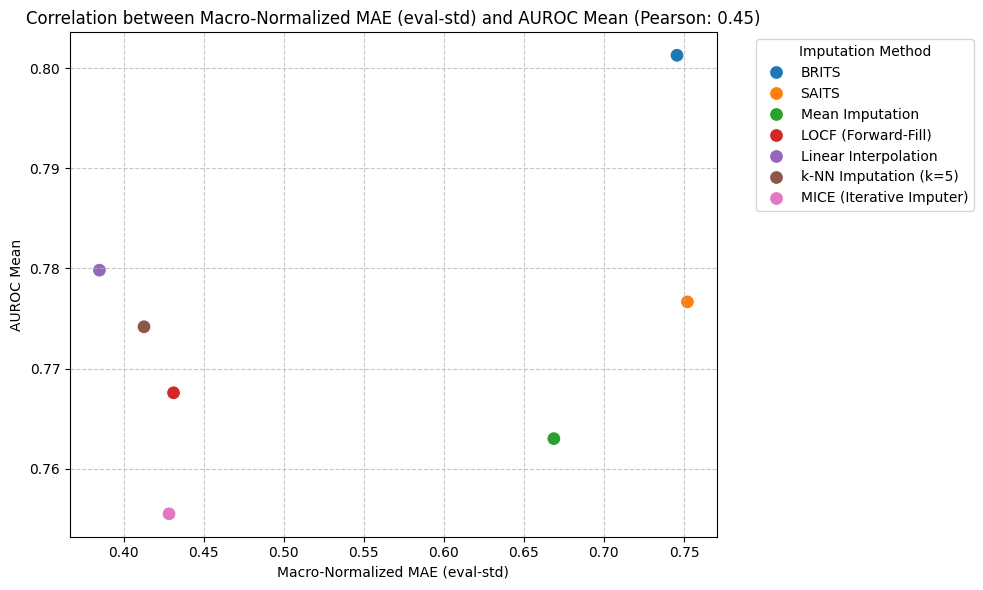

Pearson correlation coefficient between Macro-Normalized MAE (eval-std) and AUROC Mean: 0.4480


In [ ]:
# only 7 methods, so treat r as a rough guide
correlation = final_combined['macro_norm_mae_eval_std'].corr(final_combined['AUROC_mean'])

plt.figure(figsize=(10, 6))
sns.scatterplot(x='macro_norm_mae_eval_std', y='AUROC_mean', data=final_combined, hue=final_combined.index, s=100)
plt.title(f'Correlation between Macro-Normalized MAE (eval-std) and AUROC Mean (Pearson: {correlation:.2f})')
plt.xlabel('Macro-Normalized MAE (eval-std)')
plt.ylabel('AUROC Mean')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Imputation Method', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(f"Pearson r, macro-normalized MAE vs. AUROC mean: {correlation:.4f}")